In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import os

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
print(os.getcwd())

C:\Users\MADHUSMITA NAYAK


In [13]:
zip_path = r"C:\Users\MADHUSMITA NAYAK\OneDrive\PRODIGY_DS_01\Dataset\API_SP.POP.TOTL_DS2_en_csv_v2_58181.zip"
print("File exists:", os.path.exists(zip_path))

File exists: True


In [15]:
with zipfile.ZipFile(zip_path, 'r') as zip_file:
files = zip_file.namelist()
data_file = next(f for f in files if f.startswith("API_") and f.endswith(".csv"))
metadata_file = next(f for f in files if "Metadata_Country" in f and f.endswith(".csv"))
df = pd.read_csv(zip_file.open(data_file),skiprows=4)
 metadata = pd.read_csv( zip_file.open(metadata_file))
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [17]:
display(df.head())#prints first five rows

print("Dataset shape:")
print(df.shape)

print("Column names:")
print(df.columns.tolist())

print("Dataset information:")
df.info()
 

First five rows:


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54922.0,55578.0,56320.0,57002.0,57619.0,58190.0,...,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0,107995.0,108785.0,NaN
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130075728.0,133534923.0,137171659.0,140945536.0,144904094.0,149033472.0,...,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750491370.0,769280888.0,788844284.0,NaN
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,9035043.0,9214083.0,9404406.0,9604487.0,9814318.0,10036008.0,...,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0,42647492.0,43844111.0,NaN
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,97630925.0,99706674.0,101854756.0,104089175.0,106384410.0,108754449.0,...,440150152.0,451395343.0,462522286.0,473687685.0,484978794.0,496366058.0,508318102.0,520655398.0,532809933.0,NaN
4,Angola,AGO,"Population, total",SP.POP.TOTL,5231654.0,5301583.0,5354310.0,5408320.0,5464187.0,5521981.0,...,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0,37885849.0,39040039.0,NaN


Dataset shape:
(266, 71)
Column names:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', 'Unnamed: 70']
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 71 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object

In [19]:

# Removes completely empty columns
df = df.dropna(axis=1, how='all')

# Removes unnecessary unnamed columns
df = df.loc[
    :, ~df.columns.astype(str).str.contains("^Unnamed")
]

# Removes duplicate rows
df = df.drop_duplicates()

# Removes extra spaces from column names
df.columns = df.columns.astype(str).str.strip()

print("Data cleaning completed!")
print(df.shape)


Data cleaning completed!
(266, 70)


In [21]:

df = df.merge(metadata[["Country Code", "Region"]], on="Country Code", how="left")# Keeps country records using World Bank metadata
df = df[df["Region"].notna()].copy()
print("Number of countries:", len(df))


Country records selected!
Number of countries: 217


In [23]:

year_columns = [col for col in df.columns if str(col).isdigit() and len(str(col)) == 4]# Identifys columns containing years
df[year_columns] = df[year_columns].apply(pd.to_numeric, errors="coerce")# Converts population values to numeric
print("Population columns converted to numeric!")


Population columns converted to numeric!


In [25]:

print("Missing values before cleaning:")
print(df[year_columns].isnull().sum().sum())

# Remove records without population data
# Missing values are not replaced with zero
df = df.dropna(subset=year_columns, how="all")

print("\nMissing values after removing empty country records:")
print(df[year_columns].isnull().sum().sum())


Missing values before cleaning:
30

Missing values after removing empty country records:
30


In [27]:
population_data = df.melt( id_vars=["Country Name", "Country Code"],value_vars=year_columns, var_name="Year",value_name="Population")# it converts the dataset from wide format to long format
population_data = population_data.dropna(subset=["Population"])# it removes records with missing population values
population_data["Year"] = population_data["Year"].astype(int)
display(population_data.head())

Data prepared successfully!


,Country Name,Country Code,Year,Population
0,Aruba,ABW,1960,54922.0
1,Afghanistan,AFG,1960,9035043.0
2,Angola,AGO,1960,5231654.0
3,Albania,ALB,1960,1608800.0
4,Andorra,AND,1960,9510.0


In [29]:
print("Population Summary Statistics")
print(population_data["Population"].describe())
print("\nNumber of countries:")
print(population_data["Country Name"].nunique())
print("\nYears covered:")
print(population_data["Year"].min(),
      "to",
      population_data["Year"].max())


Population Summary Statistics
count    1.429200e+04
mean     2.549778e+07
std      1.063401e+08
min      2.715000e+03
25%      5.019272e+05
50%      4.278256e+06
75%      1.414610e+07
max      1.463866e+09
Name: Population, dtype: float64

Number of countries:
217

Years covered:
1960 to 2025


In [31]:

latest_year = population_data.loc[population_data["Population"].notna(), "Year"].max()
latest_data = population_data[population_data["Year"] == latest_year].copy()
print("Latest available year:", latest_year)


Latest available year: 2025


In [33]:
top_10 = latest_data.nlargest(10, "Population")

display(top_10[["Country Name", "Population"]])

,Country Name,Population
14194,India,1.463866e+09
14141,China,1.406585e+09
14308,United States,3.417849e+08
14192,Indonesia,2.857212e+08
14255,Pakistan,2.552196e+08
14247,Nigeria,2.375278e+08
14131,Brazil,2.128124e+08
14122,Bangladesh,1.756869e+08
14270,Russian Federation,1.435133e+08
14166,Ethiopia,1.354721e+08


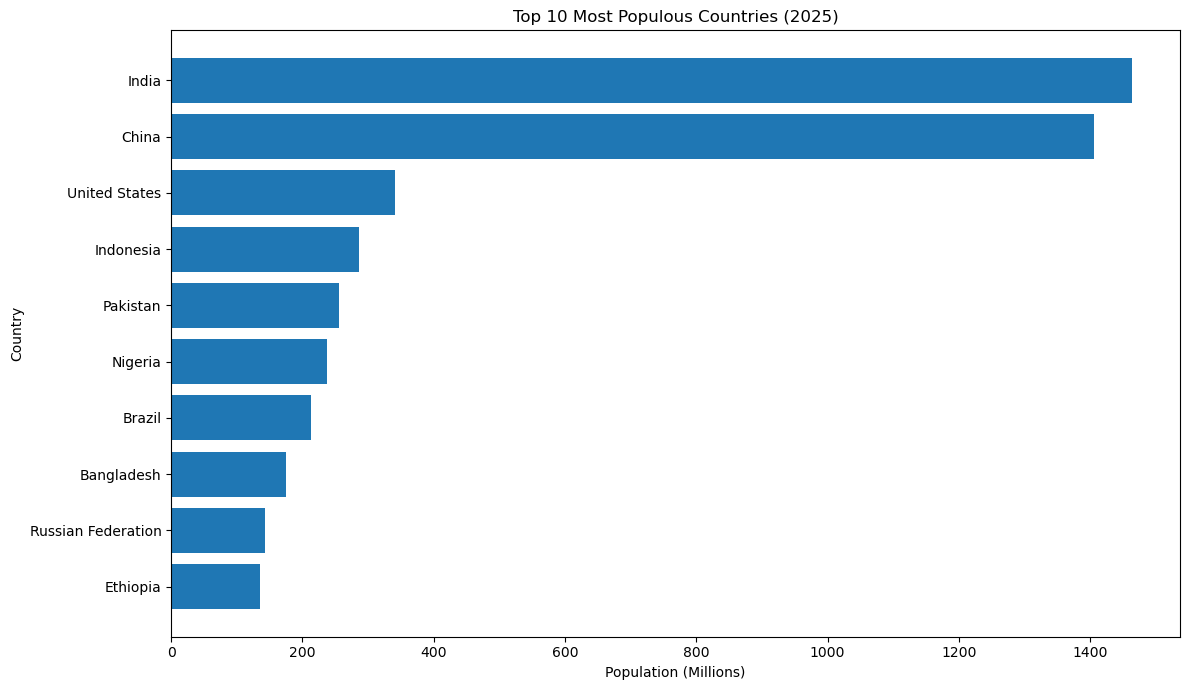

In [35]:

plt.figure(figsize=(12, 7))

plt.barh(top_10["Country Name"],top_10["Population"] / 1_000_000)

plt.xlabel("Population (Millions)")
plt.ylabel("Country")

plt.title(f"Top 10 Most Populous Countries ({latest_year})")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

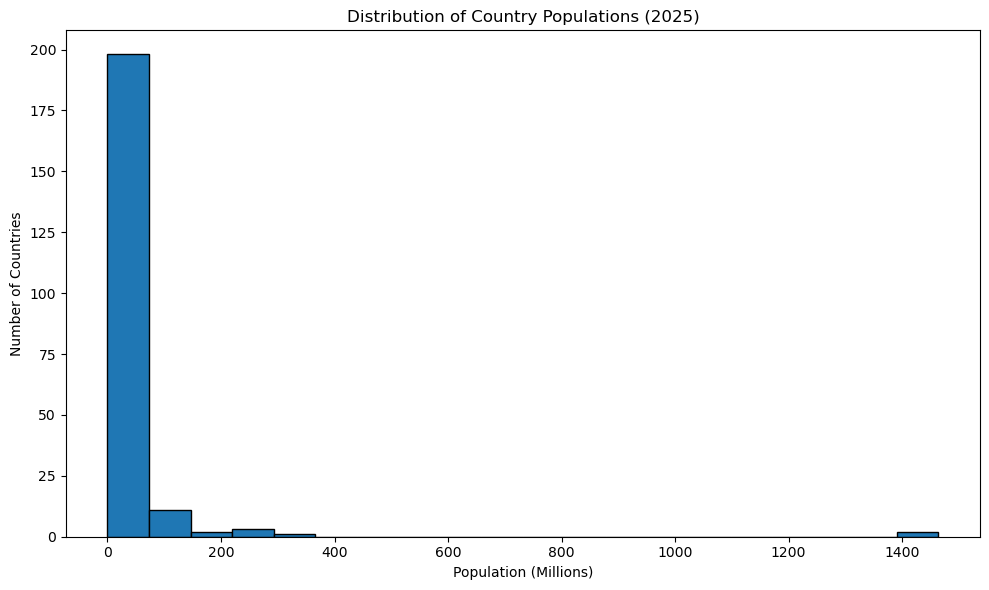

In [37]:

plt.figure(figsize=(10, 6))

plt.hist(latest_data["Population"] / 1_000_000,bins=20,edgecolor="black")
plt.xlabel("Population (Millions)")
plt.ylabel("Number of Countries")

plt.title(f"Distribution of Country Populations ({latest_year})")
plt.tight_layout()
plt.show()


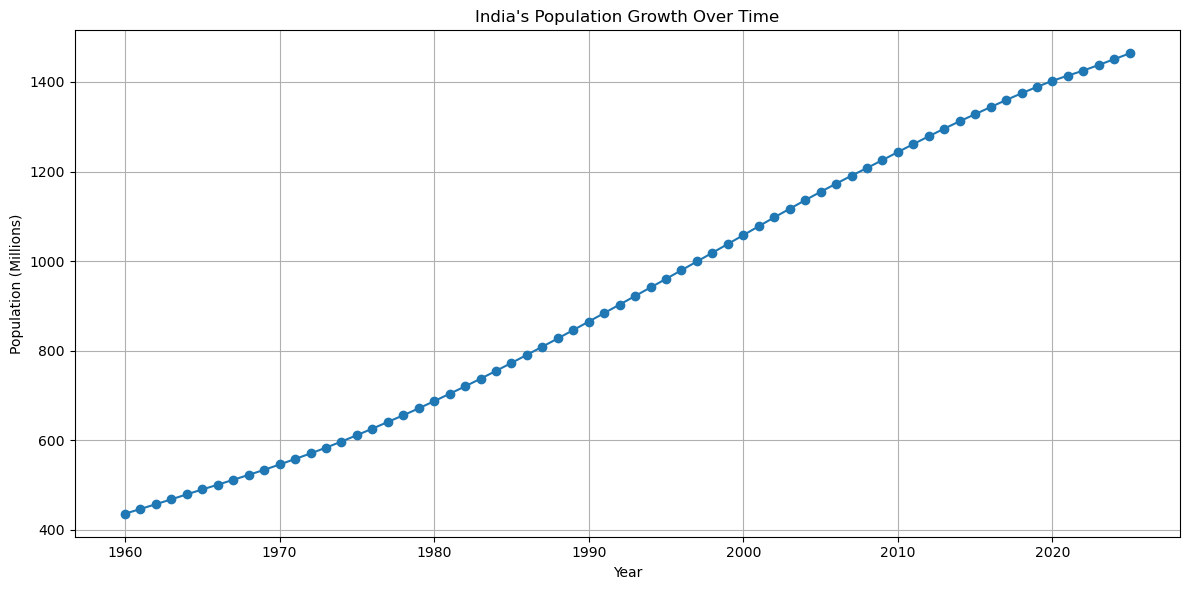

In [39]:

india_data = population_data[population_data["Country Name"] == "India"].sort_values("Year")
plt.figure(figsize=(12, 6))

plt.plot(india_data["Year"],india_data["Population"] / 1_000_000,marker="o")
plt.xlabel("Year")
plt.ylabel("Population (Millions)")
plt.title("India's Population Growth Over Time")
plt.grid(True)
plt.tight_layout()

plt.show()


In [41]:

print("PROJECT FINDINGS")
print("-----------------------------")

print(f"Latest year analysed: {latest_year}")

print("\nTop 3 most populous countries:")

for index, row in top_10.head(3).iterrows():
    print(
        row["Country Name"],
        "-",
        round(row["Population"] / 1_000_000, 2),
        "million"
    )

india_1960 = india_data.loc[
    india_data["Year"] == 1960, "Population"
]

india_latest = india_data.loc[
    india_data["Year"] == latest_year, "Population"
]

if not india_1960.empty and not india_latest.empty:
    growth = (
        (india_latest.iloc[0] - india_1960.iloc[0])
        / india_1960.iloc[0]
    ) * 100

    print(
        f"\nIndia's population growth from 1960 to "
        f"{latest_year}: {growth:.2f}%"
    )


PROJECT FINDINGS
-----------------------------
Latest year analysed: 2025

Top 3 most populous countries:
India - 1463.87 million
China - 1406.59 million
United States - 341.78 million

India's population growth from 1960 to 2025: 235.76%
